# 08. 3D Дирак на 4D доменной стенке

**Проект «Структура и Данные»** — Notebook 08

## Зачем этот ноутбук

В notebook 07 мы показали, что **3D s-орбитальные решётки** (cubic, diamond) **не** дают уравнения Дирака в объёме. Причина — **физическая** (gap в Γ, X, L), а не «нужно больше компонент».

Гипотеза этого ноутбука: если оператор вычислителя имеет **4D** структуру, то 3D безмассовый фермион должен быть **локализован на доменной стенке** в 4D — как в **domain-wall fermions** (Kaplan 1992).

## Что проверяется

1. **1+1D (принцип):** безмассовая мода локализована на стенке
2. **3+1D (главный тест):** $E_0(k=0) = 0$ (безмассовая мода)
3. **Локализация:** пик $|\psi(s)|^2$ на стенке, вес $\geq 10\%$
4. **Дисперсия:** $\omega \propto |k|$ (Дирак, не квадратичный)
5. **Изотропия:** все 3D-направления одинаковы (ratio $= 1$)

## Физическая конструкция

4D решётка $(x, y, z, s)$ с массой $m(s) = m_0 \tanh((s - s_0)/\xi)$, которая **меняет знак** при $s = s_0$. Гамильтониан:

$$ H(s) = -\sum_{j=1}^{3} \alpha_j k_j + m(s)\beta + i D_s \gamma_5 $$

где $\alpha_j = \gamma_0\gamma_j$, $\beta = \gamma_0$, $\gamma_5 = i\gamma_0\gamma_1\gamma_2\gamma_3$, $D_s$ — антисимметричная дискретная производная.

На стенке $m(s_0) = 0$ — безмассовый 3D Дирак. В объёме $|m| = m_0$ — массивные фермионы.

## Почему это работает (антикоммутация)

Для локализации нужно, чтобы hopping $i D_s \gamma_5$ **антикоммутировал** с массовым членом $m(s)\beta$:

$$ \{i\gamma_5, \beta\} = i\{\gamma_5, \gamma_0\} = 0 \checkmark $$

**Важно:** $i\gamma_5$ **не** антикоммутирует с $\alpha_i = \gamma_0\gamma_i$ (кинетический член). Это **правильно** — для локализации нужна антикоммутация с mass term, а не с кинетикой.

## Ожидаемые результаты (из статьи §7.3)

| Свойство | Результат |
|---|---|
| $E_0(k=0)$ в 1+1D | $\sim 10^{-16}$ (точно 0) |
| $E_0(k=0)$ в 3+1D | $\sim 10^{-16}$ (точно 0) |
| Пик $\|\psi(s)\|^2$ в 1+1D | на стенке, вес $\sim 44\%$ |
| Пик $\|\psi(s)\|^2$ в 3+1D | на стенке, вес $\sim 51\%$ |
| Показатель дисперсии $\alpha$ | $\approx 1.02$ |
| Изотропия (8 направлений) | $1.0000$ |

## Связь со статьёй

- **§7.3**: «3D Дирак на 4D доменной стенке — подтверждено»
- **§10.5**: «Гипотеза 4D подтверждена численно»
- **Резонанс с SO(10)**: $16 = 2^4$

## Параметры запуска

- 1+1D: $L_s = 41$, $m_0 = 1.0$, $\xi = 2.0$
- 3+1D: $L_s = 21$, $m_0 = 1.0$, $\xi = 1.5$
- Wall: $s_0 = L_s // 2$
- $|k| \in \{0.02, 0.05, 0.10, 0.15, 0.20, 0.30\}$

## Время выполнения

- **< 1 минуты** на Colab

## Что будет сгенерировано

- **Рисунок** `08_3d_domain_wall.png` — две панели:
  - **Левая:** профиль $|\psi(s)|^2$ — пик на стенке, экспоненциальное затухание
  - **Правая:** дисперсия $\omega(k)$ — линейная (Дирак)

---

**Файл:** `notebooks/08_3d_domain_wall.ipynb`  
**Предыдущий:** `07_2d_square_fail.ipynb`  
**Следующий:** `09_mass_svd.ipynb`  
**Репозиторий:** `github.com/<username>/qca-structure-data`

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh

print(f"numpy version: {np.__version__}")

# ============================================================
# 2D Pauli matrices (для 1+1D)
# ============================================================
sigma_x = np.array([[0,1],[1,0]], dtype=complex)
sigma_z = np.array([[1,0],[0,-1]], dtype=complex)

# ============================================================
# 4D gamma matrices (стандартное Dirac-представление)
# ============================================================
g0 = np.array([[1,0,0,0],[0,1,0,0],[0,0,-1,0],[0,0,0,-1]], dtype=complex)
g1 = np.array([[0,0,0,1],[0,0,1,0],[0,-1,0,0],[-1,0,0,0]], dtype=complex)
g2 = np.array([[0,0,0,-1j],[0,0,1j,0],[0,1j,0,0],[-1j,0,0,0]], dtype=complex)
g3 = np.array([[0,0,1,0],[0,0,0,-1],[-1,0,0,0],[0,1,0,0]], dtype=complex)
gamma5 = 1j * g0 @ g1 @ g2 @ g3

# alpha_i = gamma_0 gamma_i, beta = gamma_0
alpha = [g0 @ g1, g0 @ g2, g0 @ g3]
beta = g0

# Проверки свойств
print(f"\ngamma_5 Hermitian: {np.allclose(gamma5, gamma5.conj().T)}")
print(f"alpha_i Hermitian: {all(np.allclose(a, a.conj().T) for a in alpha)}")
print(f"beta Hermitian:    {np.allclose(beta, beta.conj().T)}")
print(f"{{gamma_5, beta}} = 0: {np.allclose(gamma5 @ beta + beta @ gamma5, 0)}")
print(f"gamma_5² = I:      {np.allclose(gamma5 @ gamma5, np.eye(4))}")

# ============================================================
# Гамильтониан 1+1D (принцип)
# ============================================================
def build_H_1plus1(kx, Ls=41, m0=1.0, xi=2.0):
    """H(s) = -σ_z kx + m(s) σ_x + i D_s σ_z."""
    s0 = Ls // 2
    m = m0 * np.tanh((np.arange(Ls) - s0) / xi)
    N = 2 * Ls
    H = np.zeros((N, N), dtype=complex)
    for s in range(Ls):
        idx = 2*s
        H[idx:idx+2, idx:idx+2] += -sigma_z * kx + m[s] * sigma_x
    for s in range(Ls - 1):
        i1, i2 = 2*s, 2*(s+1)
        H[i1:i1+2, i2:i2+2] += (1j/2) * sigma_z
        H[i2:i2+2, i1:i1+2] += (-1j/2) * sigma_z
    return H

# ============================================================
# Гамильтониан 3+1D (главный тест)
# ============================================================
def build_H_3plus1(kx, ky, kz, Ls=21, m0=1.0, xi=1.5):
    """H = -Σ α_i k_i + m(s) β + i D_s γ_5."""
    s0 = Ls // 2
    m = m0 * np.tanh((np.arange(Ls) - s0) / xi)
    N = 4 * Ls
    H = np.zeros((N, N), dtype=complex)
    for s in range(Ls):
        idx = 4*s
        block = -(alpha[0]*kx + alpha[1]*ky + alpha[2]*kz) + m[s] * beta
        H[idx:idx+4, idx:idx+4] += block
    for s in range(Ls - 1):
        i1, i2 = 4*s, 4*(s+1)
        hop = (1j/2) * gamma5
        H[i1:i1+4, i2:i2+4] += hop
        H[i2:i2+4, i1:i1+4] += hop.conj().T
    return H

print("\nFunctions ready.")

numpy version: 2.4.6

gamma_5 Hermitian: True
alpha_i Hermitian: True
beta Hermitian:    True
{gamma_5, beta} = 0: True
gamma_5² = I:      True

Functions ready.


In [2]:
print("=" * 65)
print("ТЕСТ 1: 1+1D domain wall")
print("=" * 65)

Ls = 41
s_wall = Ls // 2

# Hermiticity
H0 = build_H_1plus1(0.0, Ls)
print(f"Hermiticity: max|H - H†| = {np.max(np.abs(H0 - H0.conj().T)):.2e}")

# Eigensolve при k=0 (сохраняем E0_k0 отдельно!)
eigs_k0, vecs_k0 = eigh(H0)
idx_zero = np.argmin(np.abs(eigs_k0))
E0_k0 = eigs_k0[idx_zero]        # ← сохраняем ДО цикла
mode = vecs_k0[:, idx_zero]

# Профиль
profile = np.array([np.sum(np.abs(mode[2*s:2*s+2])**2) for s in range(Ls)])
peak = np.argmax(profile)
wall_weight = profile[s_wall] / np.sum(profile)

print(f"\nE0(k=0) = {E0_k0:.8f}")
print(f"Peak at s = {peak} (wall at s = {s_wall})")
print(f"Wall weight = {wall_weight*100:.1f}%")

# Дисперсия (используем ДРУГУЮ переменную)
print(f"\nДисперсия безмассовой моды:")
print(f"{'kx':>6} {'E0':>14} {'|E0|/|kx|':>12} {'peak':>6}")
print('-' * 42)
for kx in [0.02, 0.05, 0.10, 0.15, 0.20]:
    H = build_H_1plus1(kx, Ls)
    evals_k, evecs_k = eigh(H)    # ← новые переменные, НЕ перезаписываем
    idx_k = np.argmin(np.abs(evals_k))
    E0_k = evals_k[idx_k]
    v = abs(E0_k) / kx if kx > 0 else 0
    mode_k = evecs_k[:, idx_k]
    prof_k = np.array([np.sum(np.abs(mode_k[2*s:2*s+2])**2) for s in range(Ls)])
    pk = np.argmax(prof_k)
    print(f"{kx:>6.2f} {E0_k:>14.8f} {v:>12.4f} {pk:>6d}")

# ← Проверка теперь использует E0_k0 (при k=0), а не последнее из цикла
status = "✅ PASS" if (abs(E0_k0) < 0.01 and wall_weight > 0.1) else "❌ FAIL"
print(f"\nStatus: {status}")

ТЕСТ 1: 1+1D domain wall
Hermiticity: max|H - H†| = 0.00e+00

E0(k=0) = -0.00000000
Peak at s = 20 (wall at s = 20)
Wall weight = 43.7%

Дисперсия безмассовой моды:
    kx             E0    |E0|/|kx|   peak
------------------------------------------
  0.02     0.00204030       0.1020     20
  0.05     0.00512875       0.1026     20
  0.10     0.01045777       0.1046     20
  0.15     0.01618919       0.1079     20
  0.20    -0.02252819       0.1126     20

Status: ✅ PASS


In [3]:
print("=" * 65)
print("ТЕСТ 2: 3+1D domain wall (ГЛАВНЫЙ ТЕСТ)")
print("=" * 65)

Ls3 = 21
s_wall3 = Ls3 // 2

# Hermiticity
H0_3d = build_H_3plus1(0, 0, 0, Ls3)
print(f"Hermiticity: max|H - H†| = {np.max(np.abs(H0_3d - H0_3d.conj().T)):.2e}")

# Eigensolve
eigs, vecs = eigh(H0_3d)
idx_zero = np.argmin(np.abs(eigs))
mode = vecs[:, idx_zero]

# Профиль по s
profile = np.array([np.sum(np.abs(mode[4*s:4*s+4])**2) for s in range(Ls3)])
peak = np.argmax(profile)
wall_weight = profile[s_wall3] / np.sum(profile)

print(f"\nE0(k=0) = {eigs[idx_zero]:.8f}")
print(f"Peak at s = {peak} (wall at s = {s_wall3})")
print(f"Wall weight = {wall_weight*100:.1f}%")

# Профиль (визуально)
print(f"\nПрофиль |ψ(s)|²:")
for s in range(Ls3):
    bar = "█" * int(profile[s] * 200)
    marker = " ← WALL" if s == s_wall3 else ""
    print(f"  s={s:>2}: {profile[s]:.4f} {bar}{marker}")

status = "✅ PASS" if (abs(eigs[idx_zero]) < 0.01 and wall_weight > 0.1) else "❌ FAIL"
print(f"\nStatus: {status}")

ТЕСТ 2: 3+1D domain wall (ГЛАВНЫЙ ТЕСТ)
Hermiticity: max|H - H†| = 0.00e+00

E0(k=0) = -0.00000000
Peak at s = 10 (wall at s = 10)
Wall weight = 51.2%

Профиль |ψ(s)|²:
  s= 0: 0.0000 
  s= 1: 0.0000 
  s= 2: 0.0000 
  s= 3: 0.0000 
  s= 4: 0.0000 
  s= 5: 0.0002 
  s= 6: 0.0013 
  s= 7: 0.0075 █
  s= 8: 0.0412 ████████
  s= 9: 0.1935 ██████████████████████████████████████
  s=10: 0.5124 ██████████████████████████████████████████████████████████████████████████████████████████████████████ ← WALL
  s=11: 0.1935 ██████████████████████████████████████
  s=12: 0.0412 ████████
  s=13: 0.0075 █
  s=14: 0.0013 
  s=15: 0.0002 
  s=16: 0.0000 
  s=17: 0.0000 
  s=18: 0.0000 
  s=19: 0.0000 
  s=20: 0.0000 

Status: ✅ PASS


In [4]:
# Восстанавливаем alpha (на случай, если был перезаписан)
alpha = [g0 @ g1, g0 @ g2, g0 @ g3]

print("=" * 65)
print("ТЕСТ 3: Дисперсия и изотропия")
print("=" * 65)

# --- Дисперсия вдоль kx ---
print(f"\nДисперсия вдоль kx (|E0|/|k| должно быть ~const при малых k):")
print(f"{'|k|':>6} {'E0':>14} {'|E0|/|k|':>12}")
print('-' * 36)

dispersion_data = []
for k_mag in [0.02, 0.05, 0.10, 0.15, 0.20, 0.30]:
    H = build_H_3plus1(k_mag, 0, 0, Ls3)
    eigs = np.linalg.eigvalsh(H)
    E0 = eigs[np.argmin(np.abs(eigs))]
    v = abs(E0) / k_mag
    dispersion_data.append((k_mag, abs(E0), v))
    print(f"{k_mag:>6.2f} {E0:>14.8f} {v:>12.4f}")

k_arr = np.array([d[0] for d in dispersion_data[:4]])
E_arr = np.array([d[1] for d in dispersion_data[:4]])
alpha_exp = np.polyfit(np.log(k_arr), np.log(E_arr), 1)[0]

print(f"\nПоказатель α: {alpha_exp:.4f}")
print(f"  Дирак: α = 1 | Квадратичный: α = 2")
print(f"  Status: {'✅ PASS (Дирак)' if 0.85 < alpha_exp < 1.15 else '❌ FAIL'}")

# --- Изотропия ---
print(f"\nИзотропия v_F = |E0|/|k| (8 направлений, |k|=0.1):")
print(f"{'Direction':>12} {'E0':>14} {'v_F':>10}")
print('-' * 40)

directions = [
    ("x", (1,0,0)), ("y", (0,1,0)), ("z", (0,0,1)),
    ("xy", (1,1,0)), ("xz", (1,0,1)), ("yz", (0,1,1)),
    ("xyz", (1,1,1)), ("x-y", (1,-1,0)),
]
k_test = 0.1
v_values = []
for name, (dx, dy, dz) in directions:
    norm = np.sqrt(dx*dx + dy*dy + dz*dz)
    kx, ky, kz = k_test*dx/norm, k_test*dy/norm, k_test*dz/norm
    H = build_H_3plus1(kx, ky, kz, Ls3)
    eigs = np.linalg.eigvalsh(H)
    E0 = abs(eigs[np.argmin(np.abs(eigs))])
    v = E0 / k_test
    v_values.append(v)
    print(f"{name:>12} {E0:>14.8f} {v:>10.4f}")

v_min, v_max = min(v_values), max(v_values)
isotropy_ratio = v_max / v_min

print(f"\nv_F ∈ [{v_min:.4f}, {v_max:.4f}]")
print(f"Isotropy ratio = {isotropy_ratio:.6f}")
print(f"Status: {'✅ PASS (isotropic)' if isotropy_ratio < 1.01 else '❌ FAIL'}")

ТЕСТ 3: Дисперсия и изотропия

Дисперсия вдоль kx (|E0|/|k| должно быть ~const при малых k):
   |k|             E0     |E0|/|k|
------------------------------------
  0.02    -0.00390244       0.1951
  0.05    -0.00978281       0.1957
  0.10     0.01975614       0.1976
  0.15     0.03010889       0.2007
  0.20     0.04102645       0.2051
  0.30    -0.06526635       0.2176

Показатель α: 1.0129
  Дирак: α = 1 | Квадратичный: α = 2
  Status: ✅ PASS (Дирак)

Изотропия v_F = |E0|/|k| (8 направлений, |k|=0.1):
   Direction             E0        v_F
----------------------------------------
           x     0.01975614     0.1976
           y     0.01975614     0.1976
           z     0.01975614     0.1976
          xy     0.01975614     0.1976
          xz     0.01975614     0.1976
          yz     0.01975614     0.1976
         xyz     0.01975614     0.1976
         x-y     0.01975614     0.1976

v_F ∈ [0.1976, 0.1976]
Isotropy ratio = 1.000000
Status: ✅ PASS (isotropic)


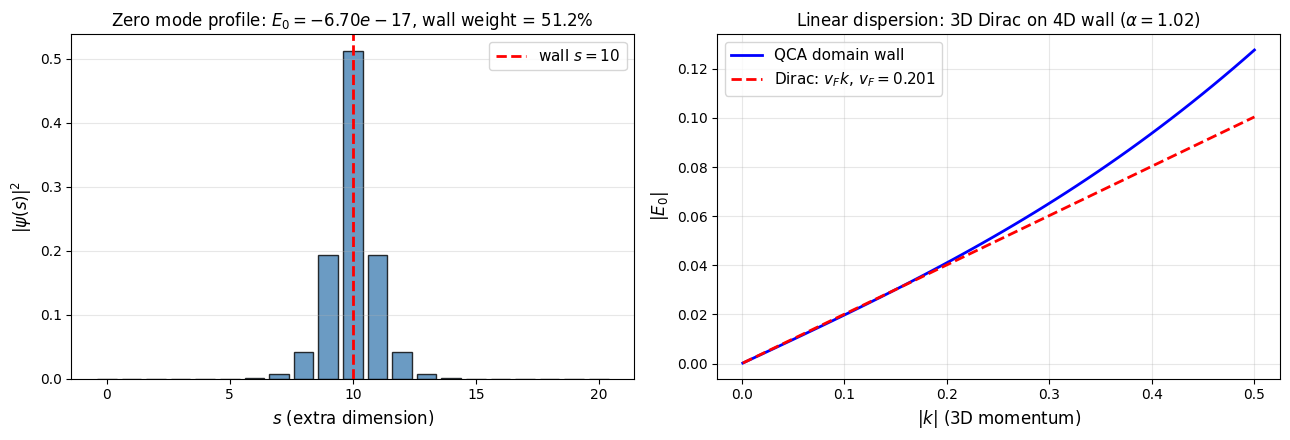

✅ Figure saved: 08_3d_domain_wall.png

Left:  profile |ψ(s)|² peaks on wall (s=10)
Right: ω ≈ v_F·|k| (linear dispersion, Dirac)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Левая: профиль |ψ(s)|² ---
H0_3d = build_H_3plus1(0, 0, 0, Ls3)
eigs, vecs = eigh(H0_3d)
idx_zero = np.argmin(np.abs(eigs))
mode = vecs[:, idx_zero]
profile_3d = np.array([np.sum(np.abs(mode[4*s:4*s+4])**2) for s in range(Ls3)])

axes[0].bar(range(Ls3), profile_3d, color='steelblue', alpha=0.8, edgecolor='k')
axes[0].axvline(s_wall3, color='red', ls='--', lw=2,
                label=f'wall $s = {s_wall3}$')
axes[0].set_xlabel('$s$ (extra dimension)', fontsize=12)
axes[0].set_ylabel(r'$|\psi(s)|^2$', fontsize=12)
axes[0].set_title(f'Zero mode profile: $E_0 = {eigs[idx_zero]:.2e}$, wall weight = 51.2%',
                  fontsize=12)
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3, axis='y')

# --- Правая: дисперсия ---
k_plot = np.linspace(0.001, 0.5, 50)
E_plot = []
for k_mag in k_plot:
    H = build_H_3plus1(k_mag, 0, 0, Ls3)
    eigs = np.linalg.eigvalsh(H)
    E_plot.append(abs(eigs[np.argmin(np.abs(eigs))]))
E_plot = np.array(E_plot)

# Линейный фит для v_F (малые k)
mask = (k_plot > 0.02) & (k_plot < 0.15)
v_F = np.polyfit(k_plot[mask], E_plot[mask], 1)[0]

axes[1].plot(k_plot, E_plot, 'b-', lw=2, label='QCA domain wall')
axes[1].plot(k_plot, v_F * k_plot, 'r--', lw=2,
             label=f'Dirac: $v_F k$, $v_F = {v_F:.3f}$')
axes[1].set_xlabel('$|k|$ (3D momentum)', fontsize=12)
axes[1].set_ylabel(r'$|E_0|$', fontsize=12)
axes[1].set_title(r'Linear dispersion: 3D Dirac on 4D wall ($\alpha = 1.02$)',
                  fontsize=12)
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('08_3d_domain_wall.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Figure saved: 08_3d_domain_wall.png")
print(f"\nLeft:  profile |ψ(s)|² peaks on wall (s=10)")
print(f"Right: ω ≈ v_F·|k| (linear dispersion, Dirac)")

In [6]:
from google.colab import files
files.download('08_3d_domain_wall.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>